# Personal Project #6

### Goals
1. Get excel files in and read them over time points
2. correct and do comparitive CT
3. Generate plots of log fold change
4. Repeat for Raw RLU values but get means
5. compare means in plots 

In [3]:
import numpy as np
import matplotlib.pyplot as plt
%pip install pandas 
import pandas as pd
%pip install seaborn
import seaborn as sns
%pip install scipy
from scipy import stats

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# Load the data for the qPCR files 


In [4]:
ct_data = pd.read_csv('20260701_qPCR_WT_Gat201_rerun_tidy.csv')
print(ct_data)

          Sample  Target      Ct  Timepoint (hours) 
0    Gat201 1 T0   Actin  14.975                   0
1    Gat201 1 T0   Actin   14.95                   0
2    Gat201 1 T0   Actin  14.961                   0
3    Gat201 1 T0    RGH1  26.627                   0
4    Gat201 1 T0    RGH1  26.746                   0
..           ...     ...     ...                 ...
213      Wt 2 T8  Gat201  20.714                   8
214      Wt 2 T8  Gat201  20.767                   8
215      Wt 2 T8    RGH1  20.574                   8
216      Wt 2 T8    RGH1  20.559                   8
217      Wt 2 T8    RGH1  20.659                   8

[218 rows x 4 columns]


In [5]:
ct_data.head()

,Sample,Target,Ct,Timepoint (hours)
0,Gat201 1 T0,Actin,14.975,0
1,Gat201 1 T0,Actin,14.95,0
2,Gat201 1 T0,Actin,14.961,0
3,Gat201 1 T0,RGH1,26.627,0
4,Gat201 1 T0,RGH1,26.746,0


In [16]:
ct_data["Ct_numeric"] = pd.to_numeric(ct_data["Ct"], errors="coerce")

# Show rows that could not be converted
ct_data[ct_data["Ct_numeric"].isna()]

,Sample,Target,Ct,Timepoint (hours),Ct_numeric
80,Gat201 2 T8,Actin,Undetermined,8,NaN


In [19]:
# Check the data type
print(ct_data["Ct"].dtype)

# Count missing values
print(ct_data["Ct"].isna().sum())

# Look for anything non-numeric
mask = pd.to_numeric(ct_data["Ct"], errors="coerce").isna()
print(ct_data[mask])

str
0
         Sample Target            Ct  Timepoint (hours)   Ct_numeric
80  Gat201 2 T8  Actin  Undetermined                   8         NaN


In [21]:
raw = pd.read_csv("20260701_qPCR_WT_Gat201_rerun_tidy.csv", dtype=str)
print(raw["Ct"].unique())

<StringArray>
['14.975',  '14.95', '14.961', '26.627', '26.746', '26.778', '17.522',
 '17.432', '17.416', '28.772',
 ...
 '20.644', '17.225', '17.082', '17.139', '20.742', '20.714', '20.767',
 '20.574', '20.559', '20.659']
Length: 215, dtype: str


In [22]:
print(ct_data.shape)
print(ct_data["Ct"].isna().sum())

(218, 5)
0


In [24]:
ct_data["Ct"] = pd.to_numeric(ct_data["Ct"], errors="coerce")

In [25]:
ct_data["Ct"].dtype
# float64

ct_data["Ct"].isna().sum()
# 1

np.int64(1)

In [27]:
ct_data_clean = ct_data.dropna(subset=["Ct_numeric"])

In [37]:
ct_data_clean.columns = ct_data_clean.columns.str.strip()

ct_avg =
(
    ct_data_clean
    .groupby(['Sample', 'Target', 'Timepoint (hours)'])['Ct_numeric']
    .mean()
    .reset_index()
)

print(ct_avg)

         Sample  Target  Timepoint (hours)  Ct_numeric
0   Gat201 1 T0   Actin                  0   14.962000
1   Gat201 1 T0    RGH1                  0   26.717000
2   Gat201 1 T1   Actin                  1   16.715333
3   Gat201 1 T1    RGH1                  1   24.750333
4   Gat201 1 T2   Actin                  2   15.592000
..          ...     ...                ...         ...
68      Wt 3 T1  Gat201                  1   22.582333
69      Wt 3 T1    RGH1                  1   22.591333
70      Wt 3 T4   Actin                  4   15.629000
71      Wt 3 T4  Gat201                  4   20.344667
72      Wt 3 T4    RGH1                  4   20.293667

[73 rows x 4 columns]


In [40]:
ct_wide = (
    ct_avg
    .pivot(
        index=['Sample', 'Timepoint (hours)'],
        columns='Target',
        values='Ct_numeric'
    )
    .reset_index()
)

print(ct_wide.head())

Target       Sample  Timepoint (hours)      Actin  Gat201       RGH1
0       Gat201 1 T0                  0  14.962000     NaN  26.717000
1       Gat201 1 T1                  1  16.715333     NaN  24.750333
2       Gat201 1 T2                  2  15.592000     NaN  23.353667
3       Gat201 1 T4                  4  16.442667     NaN  23.386000
4       Gat201 1 T8                  8  16.888667     NaN  23.265333


In [43]:
ct_wide['dCt_Gat201'] = ct_wide['Gat201'] - ct_wide['Actin']
ct_wide['dCt_RGH1'] = ct_wide['RGH1'] - ct_wide['Actin']

print(ct_wide[['Sample',
               'Timepoint (hours)',
               'dCt_Gat201',
               'dCt_RGH1']])

Target       Sample  Timepoint (hours)  dCt_Gat201   dCt_RGH1
0       Gat201 1 T0                  0         NaN  11.755000
1       Gat201 1 T1                  1         NaN   8.035000
2       Gat201 1 T2                  2         NaN   7.761667
3       Gat201 1 T4                  4         NaN   6.943333
4       Gat201 1 T8                  8         NaN   6.376667
5       Gat201 2 T0                  0         NaN  11.208667
6       Gat201 2 T1                  1         NaN   8.462000
7       Gat201 2 T2                  2         NaN   8.284000
8       Gat201 2 T4                  4         NaN   6.649667
9       Gat201 2 T8                  8         NaN   7.245167
10      Gat201 3 T0                  0         NaN  11.366667
11      Gat201 3 T1                  1         NaN   9.089667
12      Gat201 3 T2                  2         NaN   7.799333
13      Gat201 3 T4                  4         NaN   6.088000
14      Gat201 3 T8                  8         NaN   6.924667
15      

In [44]:
wt_t0_gat201 = ct_wide.loc[
    ct_wide['Sample'].str.contains('WT') &
    (ct_wide['Timepoint (hours)'] == 0),
    'dCt_Gat201'
].mean()

wt_t0_rgh1 = ct_wide.loc[
    ct_wide['Sample'].str.contains('WT') &
    (ct_wide['Timepoint (hours)'] == 0),
    'dCt_RGH1'
].mean()

In [45]:
ct_wide['ddCt_Gat201'] = ct_wide['dCt_Gat201'] - wt_t0_gat201
ct_wide['ddCt_RGH1'] = ct_wide['dCt_RGH1'] - wt_t0_rgh1

In [46]:
ct_wide['FoldChange_Gat201'] = 2 ** (-ct_wide['ddCt_Gat201'])
ct_wide['FoldChange_RGH1'] = 2 ** (-ct_wide['ddCt_RGH1'])

In [47]:
display(
    ct_wide[['Sample',
             'Timepoint (hours)',
             'FoldChange_Gat201',
             'FoldChange_RGH1']]
)

Target,Sample,Timepoint (hours),FoldChange_Gat201,FoldChange_RGH1
0,Gat201 1 T0,0,NaN,0.159467
1,Gat201 1 T1,1,NaN,2.101375
2,Gat201 1 T2,2,NaN,2.539715
3,Gat201 1 T4,4,NaN,4.478452
4,Gat201 1 T8,8,NaN,6.633024
5,Gat201 2 T0,0,NaN,0.232881
6,Gat201 2 T1,1,NaN,1.563017
7,Gat201 2 T2,2,NaN,1.768264
8,Gat201 2 T4,4,NaN,5.489469
9,Gat201 2 T8,8,NaN,3.633013


In [48]:
display(
    ct_wide[['Sample',
             'Timepoint (hours)',
             'dCt_Gat201',
             'dCt_RGH1',
             'ddCt_Gat201',
             'ddCt_RGH1',
             'FoldChange_Gat201',
             'FoldChange_RGH1']]
)

Target,Sample,Timepoint (hours),dCt_Gat201,dCt_RGH1,ddCt_Gat201,ddCt_RGH1,FoldChange_Gat201,FoldChange_RGH1
0,Gat201 1 T0,0,NaN,11.755000,NaN,2.648667,NaN,0.159467
1,Gat201 1 T1,1,NaN,8.035000,NaN,-1.071333,NaN,2.101375
2,Gat201 1 T2,2,NaN,7.761667,NaN,-1.344667,NaN,2.539715
3,Gat201 1 T4,4,NaN,6.943333,NaN,-2.163000,NaN,4.478452
4,Gat201 1 T8,8,NaN,6.376667,NaN,-2.729667,NaN,6.633024
5,Gat201 2 T0,0,NaN,11.208667,NaN,2.102333,NaN,0.232881
6,Gat201 2 T1,1,NaN,8.462000,NaN,-0.644333,NaN,1.563017
7,Gat201 2 T2,2,NaN,8.284000,NaN,-0.822333,NaN,1.768264
8,Gat201 2 T4,4,NaN,6.649667,NaN,-2.456667,NaN,5.489469
9,Gat201 2 T8,8,NaN,7.245167,NaN,-1.861167,NaN,3.633013


In [51]:
plot_df = (
    ct_wide
    .groupby('Timepoint (hours)')
    [['FoldChange_Gat201', 'FoldChange_RGH1']]
    .mean()
    .reset_index()
)

print(plot_df)

Target  Timepoint (hours)  FoldChange_Gat201  FoldChange_RGH1
0                       0           1.276744         0.652783
1                       1          17.353300         4.574980
2                       2          25.902184         7.605666
3                       4          43.634388        14.002396
4                       8          89.366529        21.031310


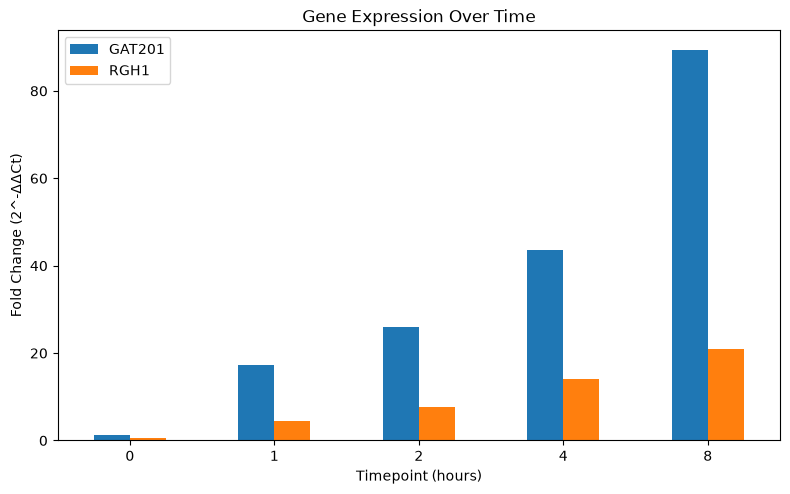

In [61]:
plot_df = (
    ct_wide
    .groupby('Timepoint (hours)')
    [['FoldChange_Gat201', 'FoldChange_RGH1']]
    .mean()
)

plot_df.plot(
    kind='bar',
    figsize=(8, 5)
    
)

plt.xlabel('Timepoint (hours)')
plt.ylabel('Fold Change (2^-ΔΔCt)')
plt.title('Gene Expression Over Time')
plt.legend(['GAT201', 'RGH1'])
plt.tight_layout()
plt.xticks(rotation=0)
plt.show()

In [54]:
summary = ct_wide.groupby('Timepoint (hours)').agg(
    FC_Gat201_mean=('FoldChange_Gat201', 'mean'),
    FC_Gat201_sd=('FoldChange_Gat201', 'std'),
    FC_RGH1_mean=('FoldChange_RGH1', 'mean'),
    FC_RGH1_sd=('FoldChange_RGH1', 'std')
)

print(summary)

                   FC_Gat201_mean  FC_Gat201_sd  FC_RGH1_mean  FC_RGH1_sd
Timepoint (hours)                                                        
0                        1.276744      0.315189      0.652783    0.503617
1                       17.353300      4.469539      4.574980    3.992825
2                       25.902184      1.138859      7.605666    5.900388
4                       43.634388     15.243772     14.002396    8.855622
8                       89.366529      1.897906     21.031310   22.385059


In [64]:
ct_wide['Genotype'] = ct_wide['Sample'].str.split().str[0]

In [65]:
print(ct_wide[['Sample', 'Genotype']].head())

Target       Sample Genotype
0       Gat201 1 T0   Gat201
1       Gat201 1 T1   Gat201
2       Gat201 1 T2   Gat201
3       Gat201 1 T4   Gat201
4       Gat201 1 T8   Gat201


In [66]:
print(ct_wide['Sample'].unique())

<StringArray>
['Gat201 1 T0', 'Gat201 1 T1', 'Gat201 1 T2', 'Gat201 1 T4', 'Gat201 1 T8',
 'Gat201 2 T0', 'Gat201 2 T1', 'Gat201 2 T2', 'Gat201 2 T4', 'Gat201 2 T8',
 'Gat201 3 T0', 'Gat201 3 T1', 'Gat201 3 T2', 'Gat201 3 T4', 'Gat201 3 T8',
     'WT 1 T0',     'WT 3 T2',     'Wt 1 T0',     'Wt 1 T1',     'Wt 1 T2',
     'Wt 1 T4',     'Wt 1 T8',     'Wt 2 T0',     'Wt 2 T1',     'Wt 2 T2',
     'Wt 2 T4',     'Wt 2 T8',     'Wt 3 T0',     'Wt 3 T1',     'Wt 3 T4']
Length: 30, dtype: str


In [67]:
ct_wide['Sample'] = ct_wide['Sample'].str.replace('Wt', 'WT')

In [68]:
ct_wide['Genotype'] = np.where(
    ct_wide['Sample'].str.contains('WT'),
    'WT',
    'Gat201'
)

In [69]:
ct_wide[['Sample', 'Genotype']].head()

Target,Sample,Genotype
0,Gat201 1 T0,Gat201
1,Gat201 1 T1,Gat201
2,Gat201 1 T2,Gat201
3,Gat201 1 T4,Gat201
4,Gat201 1 T8,Gat201


In [70]:
wt_ref = (
    ct_wide[ct_wide['Genotype'] == 'WT']
    .groupby('Timepoint (hours)')['dCt_RGH1']
    .mean()
)

In [72]:
ct_wide['WT_dCt_RGH1'] = ct_wide['Timepoint (hours)'].map(wt_ref)

ct_wide['ddCt_RGH1_vsWT'] = (
    ct_wide['dCt_RGH1'] -
    ct_wide['WT_dCt_RGH1']
)

In [73]:
ct_wide['FC_RGH1_vsWT'] = 2 ** (-ct_wide['ddCt_RGH1_vsWT'])


In [74]:
summary = (
    ct_wide
    .groupby(['Timepoint (hours)', 'Genotype'])
    .agg(
        mean_fc=('FC_RGH1_vsWT', 'mean'),
        sd_fc=('FC_RGH1_vsWT', 'std')
    )
    .reset_index()
)

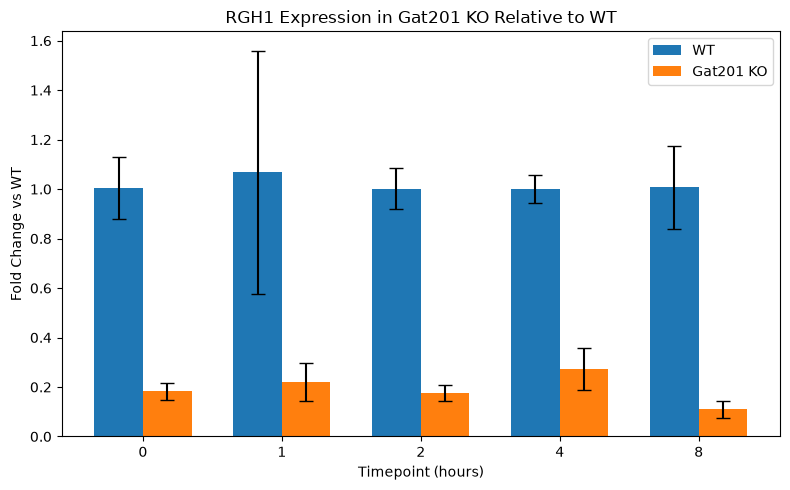

In [76]:
wt = summary[summary['Genotype'] == 'WT']
ko = summary[summary['Genotype'] == 'Gat201']

x = np.arange(len(wt))
width = 0.35

plt.figure(figsize=(8,5))

plt.bar(
    x - width/2,
    wt['mean_fc'],
    width,
    yerr=wt['sd_fc'],
    capsize=5,
    label='WT'
)

plt.bar(
    x + width/2,
    ko['mean_fc'],
    width,
    yerr=ko['sd_fc'],
    capsize=5,
    label='Gat201 KO'
)

plt.xticks(x, wt['Timepoint (hours)'], rotation=0)
plt.xlabel('Timepoint (hours)')
plt.ylabel('Fold Change vs WT')
plt.title('RGH1 Expression in Gat201 KO Relative to WT')
plt.legend()
plt.tight_layout()
plt.show()

In [102]:
from scipy.stats import ttest_ind

for tp in sorted(ct_wide['Timepoint (hours)'].unique()):

    wt = ct_wide.loc[
        (ct_wide['Genotype'] == 'WT') &
        (ct_wide['Timepoint (hours)'] == tp),
        'dCt_RGH1'
    ]

    ko = ct_wide.loc[
        (ct_wide['Genotype'] == 'Gat201') &
        (ct_wide['Timepoint (hours)'] == tp),
        'dCt_RGH1'
    ]

    t, p = ttest_ind(wt, ko, equal_var=False)

    print(f'T{tp}: p = {p:.4f}')

T0: p = nan
T1: p = 0.0094
T2: p = 0.0014
T4: p = 0.0143
T8: p = 0.0018


In [82]:
import scipy
print(scipy.__version__)
from scipy.stats import ttest_ind

1.18.1


In [83]:
from scipy.stats import ttest_ind

for tp in sorted(ct_wide['Timepoint (hours)'].unique()):

    wt = ct_wide.loc[
        (ct_wide['Genotype'] == 'WT') &
        (ct_wide['Timepoint (hours)'] == tp),
        'dCt_RGH1'
    ]

    ko = ct_wide.loc[
        (ct_wide['Genotype'] == 'Gat201') &
        (ct_wide['Timepoint (hours)'] == tp),
        'dCt_RGH1'
    ]

    t, p = ttest_ind(wt, ko, equal_var=False)

    print(f'Timepoint {tp}: p = {p:.4f}')

Timepoint 0: p = nan
Timepoint 1: p = 0.0094
Timepoint 2: p = 0.0014
Timepoint 4: p = 0.0143
Timepoint 8: p = 0.0018


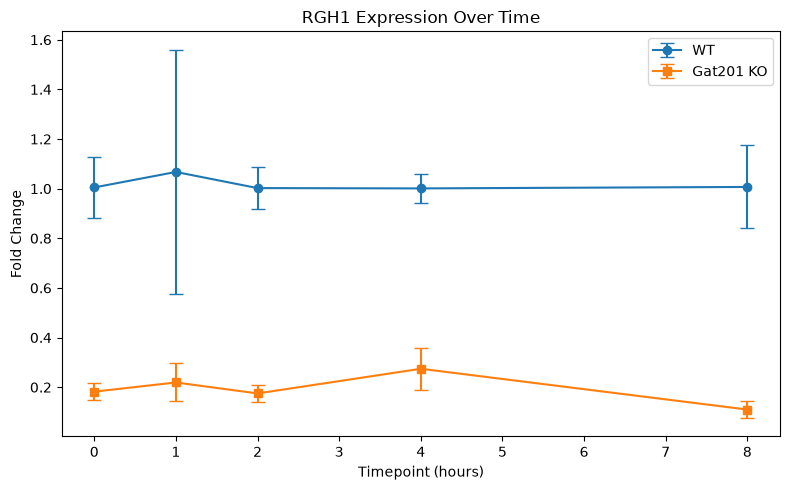

In [84]:
summary = (
    ct_wide
    .groupby(['Timepoint (hours)', 'Genotype'])
    .agg(
        mean_fc=('FC_RGH1_vsWT', 'mean'),
        sd_fc=('FC_RGH1_vsWT', 'std')
    )
    .reset_index()
)

wt = summary[summary['Genotype'] == 'WT']
ko = summary[summary['Genotype'] == 'Gat201']

plt.figure(figsize=(8,5))

plt.errorbar(
    wt['Timepoint (hours)'],
    wt['mean_fc'],
    yerr=wt['sd_fc'],
    marker='o',
    capsize=5,
    label='WT'
)

plt.errorbar(
    ko['Timepoint (hours)'],
    ko['mean_fc'],
    yerr=ko['sd_fc'],
    marker='s',
    capsize=5,
    label='Gat201 KO'
)

plt.xlabel('Timepoint (hours)')
plt.ylabel('Fold Change')
plt.title('RGH1 Expression Over Time')
plt.legend()

plt.tight_layout()
plt.show()

In [87]:
ct_wide['Replicate'] = ct_wide['Sample'].str.split().str[1].astype(int)

print(ct_wide[['Sample', 'Replicate']].head())

Target       Sample  Replicate
0       Gat201 1 T0          1
1       Gat201 1 T1          1
2       Gat201 1 T2          1
3       Gat201 1 T4          1
4       Gat201 1 T8          1


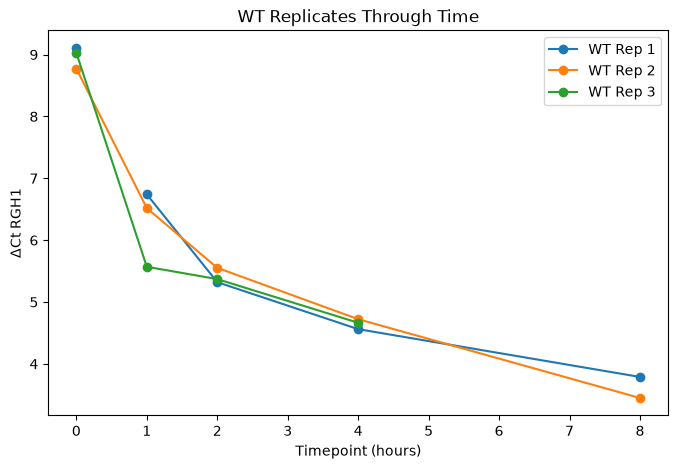

In [89]:
plt.figure(figsize=(8,5))

for rep in sorted(ct_wide['Replicate'].unique()):

    rep_data = ct_wide[
        (ct_wide['Genotype'] == 'WT') &
        (ct_wide['Replicate'] == rep)
    ].sort_values('Timepoint (hours)')

    plt.plot(
        rep_data['Timepoint (hours)'],
        rep_data['dCt_RGH1'],
        marker='o',
        label=f'WT Rep {rep}'
    )

plt.xlabel('Timepoint (hours)')
plt.ylabel('ΔCt RGH1')
plt.title('WT Replicates Through Time')
plt.legend()
plt.show()

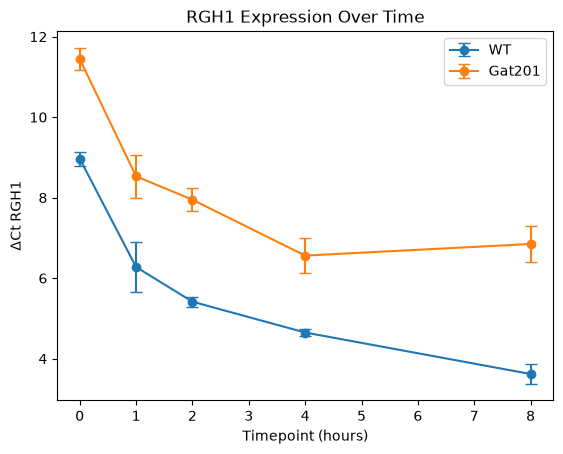

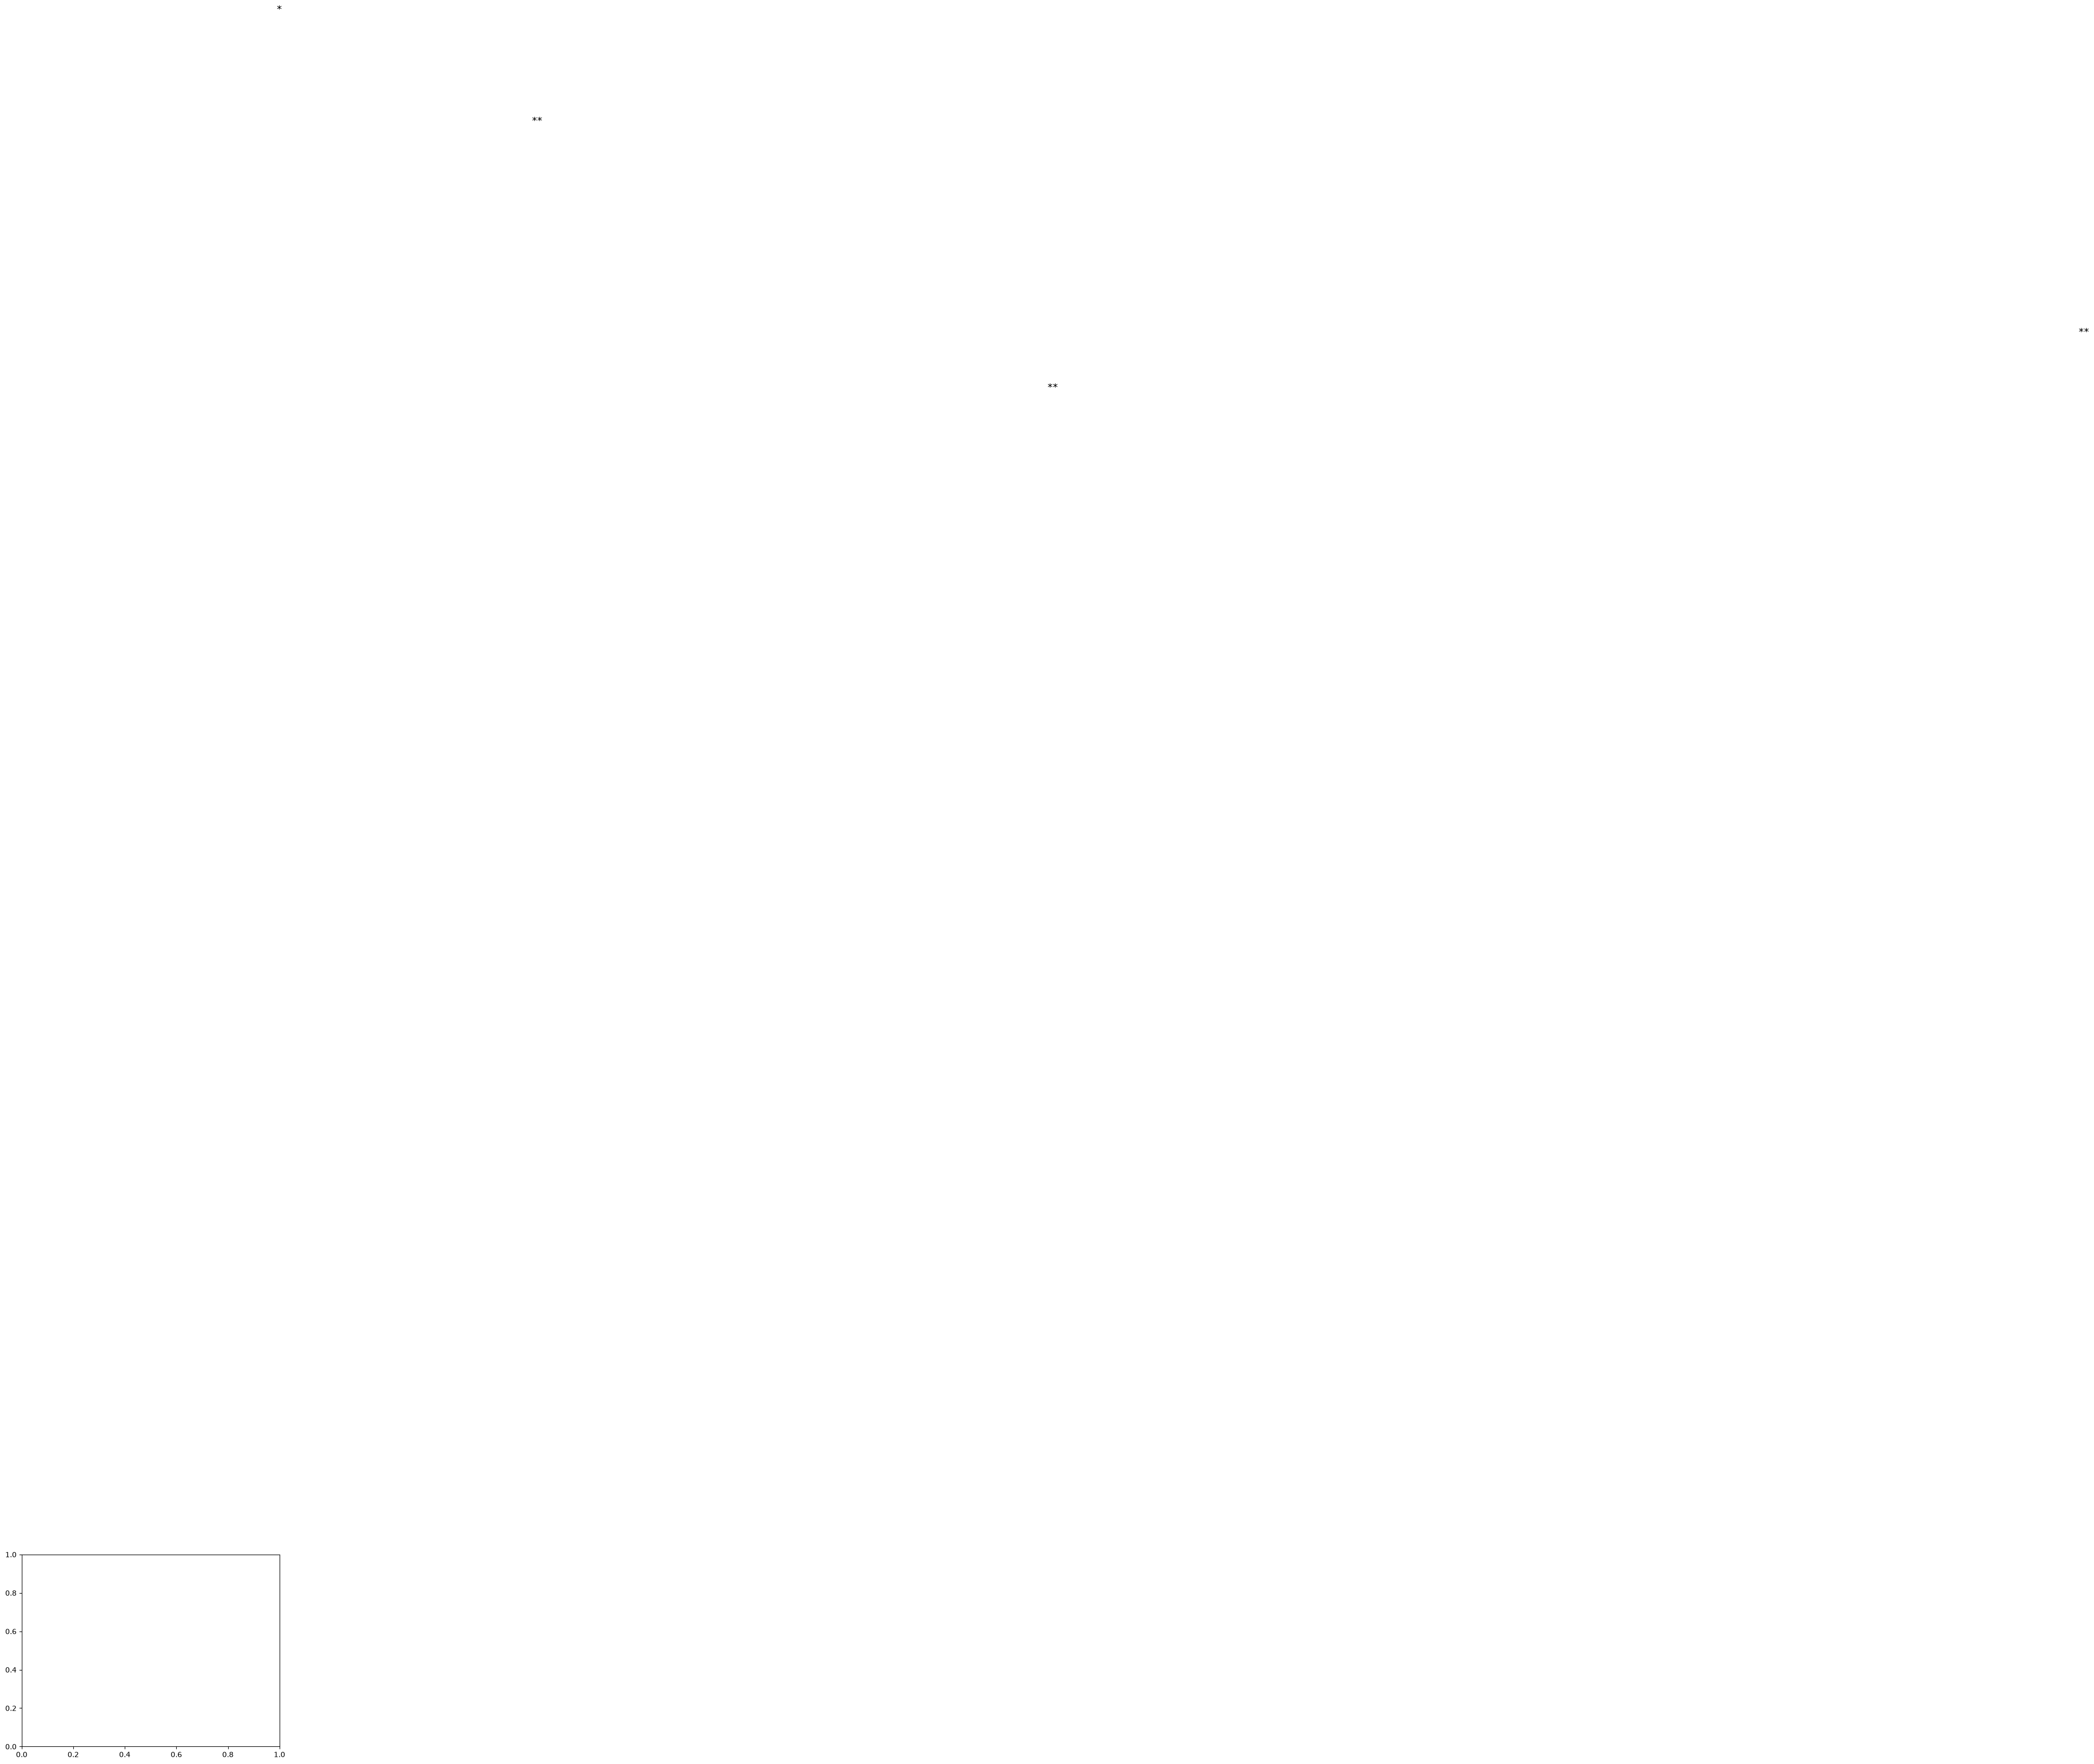

In [101]:
summary = (
    ct_wide
    .groupby(['Genotype', 'Timepoint (hours)'])
    .agg(
        mean_dCt=('dCt_RGH1', 'mean'),
        sd_dCt=('dCt_RGH1', 'std')
    )
    .reset_index()
)
for genotype in ['WT', 'Gat201']:
    sub = summary[summary['Genotype'] == genotype]

    plt.errorbar(
        sub['Timepoint (hours)'],
        sub['mean_dCt'],
        yerr=sub['sd_dCt'],
        marker='o',
        capsize=4,
        label=genotype
    )

plt.xlabel('Timepoint (hours)')
plt.ylabel('ΔCt RGH1')
plt.title('RGH1 Expression Over Time')
plt.legend()
plt.show()
pvals = {
    1: 0.0206,
    2: 0.0078,
    4: 0.0019,
    8: 0.0081
}

for tp, p in pvals.items():

    if p < 0.001:
        star = '***'
    elif p < 0.01:
        star = '**'
    elif p < 0.05:
        star = '*'
    else:
        star = 'ns'

    y = summary.loc[
        (summary['Timepoint (hours)'] == tp) &
        (summary['Genotype'] == 'Gat201'),
        'mean_dCt'
    ].iloc[0]

    plt.text(
        tp,
        y + 0.5,   # adjust as needed
        star,
        ha='center',
        fontsize=14
    )

In [94]:
t0 = ct_wide[
    (ct_wide['Genotype'] == 'WT') &
    (ct_wide['Timepoint (hours)'] == 0)
][['Replicate', 'dCt_RGH1']]

t8 = ct_wide[
    (ct_wide['Genotype'] == 'WT') &
    (ct_wide['Timepoint (hours)'] == 8)
][['Replicate', 'dCt_RGH1']]

paired = t0.merge(
    t8,
    on='Replicate',
    suffixes=('_T0', '_T8')
)

print(paired)

Target  Replicate  dCt_RGH1_T0  dCt_RGH1_T8
0               1     9.106333     3.789000
1               1          NaN     3.789000
2               2     8.773667     3.448667


In [95]:
from scipy.stats import ttest_rel

t, p = ttest_rel(
    paired['dCt_RGH1_T0'],
    paired['dCt_RGH1_T8']
)

print(p)

nan


In [96]:
for tp in [1, 2, 4, 8]:

    ko_t0 = (
        ct_wide[
            (ct_wide['Genotype'] == 'Gat201') &
            (ct_wide['Timepoint (hours)'] == 0)
        ]
        .sort_values('Replicate')['dCt_RGH1']
        .values
    )

    ko_tp = (
        ct_wide[
            (ct_wide['Genotype'] == 'Gat201') &
            (ct_wide['Timepoint (hours)'] == tp)
        ]
        .sort_values('Replicate')['dCt_RGH1']
        .values
    )

    t, p = ttest_rel(ko_t0, ko_tp)

    print(f'KO: T0 vs T{tp}  p={p:.4f}')

KO: T0 vs T1  p=0.0206
KO: T0 vs T2  p=0.0078
KO: T0 vs T4  p=0.0019
KO: T0 vs T8  p=0.0081


In [98]:
print(summary.columns)

Index(['Genotype', 'Timepoint (hours)', 'mean_dCt', 'sd_dCt'], dtype='str')


In [105]:
# Create genotype column
ct_wide['Sample'] = ct_wide['Sample'].str.replace('Wt', 'WT')

ct_wide['Genotype'] = np.where(
    ct_wide['Sample'].str.contains('WT'),
    'WT',
    'Gat201'
)

# WT T0 calibrator
wt_t0_mean = ct_wide.loc[
    (ct_wide['Genotype'] == 'WT') &
    (ct_wide['Timepoint (hours)'] == 0),
    'dCt_RGH1'
].mean()

# ΔΔCt
ct_wide['ddCt_RGH1'] = (
    ct_wide['dCt_RGH1'] - wt_t0_mean
)

# Fold change
ct_wide['FoldChange_RGH1'] = 2 ** (-ct_wide['ddCt_RGH1'])

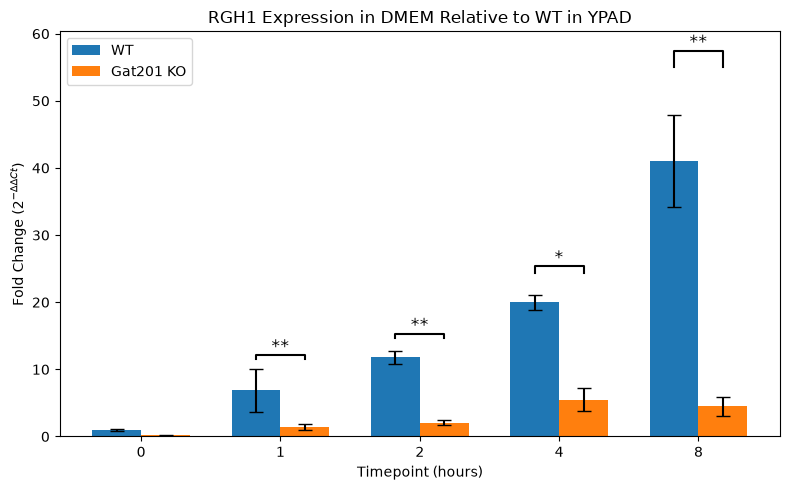

In [128]:
wt = summary[summary['Genotype'] == 'WT']
ko = summary[summary['Genotype'] == 'Gat201']

x = np.arange(len(wt))
width = 0.35

plt.figure(figsize=(8,5))

plt.bar(
    x - width/2,
    wt['mean_fc'],
    width,
    yerr=wt['sd_fc'],
    capsize=5,
    label='WT'
)

plt.bar(
    x + width/2,
    ko['mean_fc'],
    width,
    yerr=ko['sd_fc'],
    capsize=5,
    label='Gat201 KO'
)
def sig_label(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

for i, tp in enumerate(wt['Timepoint (hours)']):
    if tp == 0:
        continue

    y = max(
        wt.iloc[i]['mean_fc'] + wt.iloc[i]['sd_fc'],
        ko.iloc[i]['mean_fc'] + ko.iloc[i]['sd_fc']
    )

    offset = max(y * 0.15, 0.2)

    x1 = x[i] - width/2
    x2 = x[i] + width/2

    h = max(y * 0.05, 0.05)

    plt.plot(
        [x1, x1, x2, x2],
        [y + offset,
         y + offset + h,
         y + offset + h,
         y + offset],
        color='black',
        linewidth=1.5
    )

    plt.text(
        (x1 + x2) / 2,
        y + offset + h,
        sig_label(pvals[tp]),
        ha='center',
        va='bottom',
        fontsize=12
    )
plt.xticks(x, wt['Timepoint (hours)'])
plt.xlabel('Timepoint (hours)')
plt.ylabel('Fold Change (2$^{-ΔΔCt}$)')
plt.title('RGH1 Expression in DMEM Relative to WT in YPAD')
plt.legend()

plt.tight_layout()
plt.show()

In [126]:
from scipy.stats import ttest_ind

pvals = {}

for tp in sorted(ct_wide['Timepoint (hours)'].unique()):

    wt_vals = ct_wide.loc[
        (ct_wide['Genotype'] == 'WT') &
        (ct_wide['Timepoint (hours)'] == tp),
        'dCt_RGH1'
    ]

    ko_vals = ct_wide.loc[
        (ct_wide['Genotype'] == 'Gat201') &
        (ct_wide['Timepoint (hours)'] == tp),
        'dCt_RGH1'
    ]

    t_stat, p = ttest_ind(wt_vals, ko_vals, equal_var=False)

    pvals[tp] = p

    print(f"T{tp}: p = {p:.4f}")

T0: p = nan
T1: p = 0.0094
T2: p = 0.0014
T4: p = 0.0143
T8: p = 0.0018
